# Screen of Dysbiosis Definitions (Recalled Species)

A broad screen of ways to define "dysbiotic" plants from the **microbiome** or from **non-defense parts of the transcriptome**, written to run unattended over a weekend. It follows on from `dysbiosis_threshold_sweep_de.ipynb` (rare/core thresholds) and `dysbiosis_alternative_groupings_de.ipynb` (a first set of non-circular measures).

## Options screened

**A. Rare vs common species**
1. Rare-species excess at prevalence < 5%, 10%, 20%, 30%
2. Rare-species richness (number of rare species present)
3. Core-species loss at prevalence > 70%, 80%, 90% (low core abundance)
4. Number of core species missing
5. Accessory-species abundance (10–80% prevalence)
6. "Private" species: % of reads in species no other plant at that timepoint carries
7. Newcomers: % of reads in species not seen in any plant earlier in the same series (seasonal, circadian 1, circadian 2)

**B. Community structure**
1. Low Shannon diversity; low and high richness; low evenness
2. Dominance (% of reads in the top species)
3. Atypicality: Bray-Curtis and Aitchison (CLR) distance from the other plants at the same timepoint
4. Instability: Bray-Curtis distance from the previous timepoint's community
5. Multivariate outlier score (isolation forest on within-timepoint CLR)
6. Seasonal mismatch: the microbiome "looks" like a different time of season (cross-validated prediction of sampling day from the microbiome vs the real day; absolute and signed)
7. Community states: k-means clusters (k = 2–6) of the CLR community, with and without the timepoint effect removed; each cluster vs the rest

**C. Taxonomic composition**
1. Blooms of every phylum, class, order, family, genus and species present in ≥ 20% of seasonal samples (top 15% within timepoint)
2. Depletion of every core taxon (> 80% prevalence) at those ranks
3. Putative pathogen genera combined (*Pseudomonas*, *Xanthomonas*, *Pantoea*, *Clavibacter*, *Curtobacterium*, *Ralstonia*, *Agrobacterium*, *Rhodococcus*, *Stenotrophomonas*, *Burkholderia*) and all *Pseudomonas*
4. Ratios: Pseudomonadota : Actinomycetota (both directions), *Pseudomonas* : *Sphingomonas* (a known protective genus against *P. syringae*)

**D. Soil**
1. Soil-likeness: Bray-Curtis similarity to the soil community at the same timepoint
2. % of reads in species that are core in soil but not core in plants

**E. Microbial load (qPCR-like, from host-normalised reads)**
1. High and low bacterial load (`ham16s`); high fungal load (`hamits`); high fungal : bacterial ratio

**F. Non-defense transcriptome signatures** (all immune genes removed first: the 148-gene defense list, every gene under the defense GO terms, Luke's non-self-recognition set and the shared flg22-induced genes)
1. GO-process scores, high and low: photosynthesis, response to light / high light / UV-B, hypoxia, water deprivation, salt, cold, heat, oxidative stress, unfolded protein, leaf senescence, autophagy, ribosome biogenesis, translation, cell division, cell wall organisation, phosphate and iron starvation, nitrate assimilation, sucrose, auxin, ABA, cytokinin, gibberellin, brassinosteroid, karrikin, circadian rhythm, flavonoid and anthocyanin biosynthesis. Hormone and metabolism terms tied to defense (SA, JA, ethylene, wounding, glucosinolates) are left out.
2. Principal components 1–8 of the non-immune transcriptome (within timepoint), high and low
3. Transcriptome outliers (distance from the timepoint centre in the first 20 PCs)
4. Non-immune co-expression modules (eigengene high and low)
5. Unmapped-read fraction of the RNA-seq library (high: possibly more microbial RNA; low)

**G. Calibration**: 5 random groupings of the same size, to show how many DE genes appear by chance.

## How each option is judged

- **Microbiome definitions (A–E):** DESeq2 `~timepoint + group` (dysbiotic = top 10% and 20% within timepoint for A, B, D, E; top 15% for C; clusters as they are). The aggregate measures in A, B, D, E are also run as a **continuous** covariate, `~timepoint + measure` (within-timepoint z-score), which uses every sample. Also: timepoint-adjusted defense-score difference, and DE genes outside the defense set.
- **Transcriptome definitions (F):** no DESeq2. A group defined from expression trivially has DE genes, so a gene count would be circular. Instead: does the group's **microbiome** differ (PERMANOVA on within-timepoint CLR, with permutations inside timepoints), how do load, diversity, atypicality, rare abundance and *P. viridiflava* differ, and does the group have a higher defense score? A transcriptome signature that tracks the microbiome is a candidate readout of dysbiosis.
- Everything defines groups **within timepoint**, so groups are spread across the season (timepoint is in the DESeq2 design).
- The defense score is never used to define a group; it is only used to describe the groups afterwards.

## Running and resuming

- About 600 DESeq2 fits at ~1.5–3 min each, so roughly 15–30 hours. Fits are ordered so the broad definitions run first, and each one is cached in `Generated_data/dysbiosis_definition_screen_recalled_species/fits/` as soon as it finishes, with a line added to `progress.log` there.
- If the run stops, re-running the notebook skips cached fits and continues.
- To summarise partial results without fitting anything new, set `run_missing_fits = False` and run the notebook; unfitted definitions are listed as "not fitted".

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import contextlib
import io
import time
from pathlib import Path
import statsmodels.formula.api as smf
from scipy.stats import zscore
from scipy.spatial.distance import braycurtis, squareform
from scipy.cluster.hierarchy import linkage, fcluster
from statsmodels.stats.multitest import multipletests
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import GroupKFold, cross_val_predict
from skbio.diversity.alpha import shannon
import pydeseq2.default_inference
import pydeseq2.ds
import pydeseq2.dds
import Go_tools

###Define Thresholds
aggregate_group_fractions = [0.1, 0.2]  # groups for A, B, D, E
taxon_group_fraction = 0.15  # groups for C
signature_group_fraction = 0.15  # groups for F
min_taxon_prevalence = 0.2  # seasonal prevalence for the taxon bloom sweep
core_prevalence_threshold = 0.8
clr_min_prevalence = 0.1
log_pseudocount = 0.05  # % of reads, the table's detection floor
cluster_ks = [2, 3, 4, 5, 6]
min_cluster_size = 20
max_cluster_fraction = 0.5
n_random_groupings = 5
n_permutations = 999
min_signature_genes = 10
n_signature_pcs = 8
n_module_genes = 3000
module_cut_height = 0.5
min_module_size = 20
max_modules = 15
expressed_gene_reads_threshold = 2000
number_of_samples_expressed_in_threshold = 21

### Running
run_missing_fits = True  # False: only summarise fits already cached
max_new_fits = int(os.environ.get("SCREEN_MAX_NEW_FITS", "-1"))  # -1 = no limit (for test runs)
n_cpus = 10
results_dir = Path(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/dysbiosis_definition_screen_recalled_species"
)
(results_dir / "fits").mkdir(parents=True, exist_ok=True)
random_generator = np.random.default_rng(0)

In [2]:
transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_tpm_normalized.csv",
    index_col=0,
)
rows_to_drop_expression_data = [
    "A2450525897_n01_undetermined",
    "A2449446903_n01_undetermined",
    "B250508004_n01_undetermined",
    "B2449500127_n01_undetermined",
]
transcriptome = transcriptome.drop(index=rows_to_drop_expression_data)
transcriptome = transcriptome.sort_index()
metadata = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Plates_1_to_5_metadata_merged_luke.csv",
    index_col=0,
)
raw_transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_for_norm.csv",
    index_col=0,
)

## Get plate 5 samples and remove what they replaced from the metadata to avoid duplicates
plate_5_replacements = metadata.loc[metadata["rnaprepplate"] == "LICRNA_05"]
non_plate_5_samples = metadata.loc[metadata["rnaprepplate"] != "LICRNA_05"]
replaced_samples = non_plate_5_samples.loc[
    non_plate_5_samples["sampID"].isin(plate_5_replacements["sampID"])
]
trimmed_metadata = metadata.drop(index=replaced_samples.index)
### For remaining duplicated sampIDs, drop the transcriptome with fewer total reads
double_duplicates = (
    trimmed_metadata.loc[trimmed_metadata.duplicated(subset="sampID", keep=False)]
    .sort_values(by="Total Reads")
    .drop_duplicates(subset="sampID", keep="first")
)
trimmed_metadata = trimmed_metadata.drop(index=double_duplicates.index)
### Drop failed libraries with too few reads (e.g. LIC162 has 66 total reads)
min_total_reads = 250_000
low_read_samples = trimmed_metadata.index[trimmed_metadata["Total Reads"] < min_total_reads]
trimmed_metadata = trimmed_metadata.drop(index=low_read_samples)
print(f"Dropped {len(low_read_samples)} transcriptomes with < {min_total_reads:,} total reads")
trimmed_transcriptome = transcriptome.loc[trimmed_metadata.index]
trimmed_raw_transcriptome = raw_transcriptome.loc[trimmed_metadata.index]
print("Transcriptomes after removing replicates:", len(trimmed_metadata))

# Same gene filters as the dysbiosis DE notebook
cleaned_raw_transcriptome = trimmed_raw_transcriptome.loc[
    :, trimmed_raw_transcriptome.sum() > expressed_gene_reads_threshold
]
cleaned_raw_transcriptome = cleaned_raw_transcriptome.loc[
    :, (cleaned_raw_transcriptome > 1).sum() > number_of_samples_expressed_in_threshold
]
print("Genes kept for DESeq2:", cleaned_raw_transcriptome.shape[1])

# Defense score: only used to describe the groups, never to define them
defense_gene_list = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/load_correlated_genes_union_GO_and_FLG_plates_1_to_5.csv"
)
defense_genes = set(defense_gene_list["gene"])
transcriptome_in_defense_gene_list = trimmed_transcriptome.loc[
    :, trimmed_transcriptome.columns.isin(defense_genes)
]
trimmed_metadata["Defense Score"] = transcriptome_in_defense_gene_list.apply(zscore).sum(
    axis=1
) / len(defense_gene_list)

# Old species-level DE genes (59, plates 1-5), for overlap
old_de_genes = set(
    pd.read_csv(
        "/Users/michael/Data/Luke_terrace_experiment/General_data/Junk_data/large_deseq_gene_list_all_plates.csv",
        header=None,
    )[0]
)

Dropped 6 transcriptomes with < 250,000 total reads


Transcriptomes after removing replicates: 426
Genes kept for DESeq2: 18032


## Microbiome data

In [3]:
### Recalled species table. Species under 0.05% of a sample (AbundR == 0) are
### dropped, as in the recalled-genera table
min_abundR = 1
### Plant samples missing from the recalled-genera table (LIC148, LIC162, LIC584 have
### < 1,600 16S reads; LIC577 unknown). Kept for now: see to_revisit.txt
samples_to_drop = []  # ["LIC148", "LIC162", "LIC577", "LIC584"]
microbiome_abundance = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Oct_2026_recalled_species/lic16s_species_relabund.csv"
)
microbiome_abundance = microbiome_abundance.loc[
    (microbiome_abundance["AbundR"] >= min_abundR)
    & ~microbiome_abundance["Sample"].isin(samples_to_drop)
].copy()
# No seascirc column in the species table: circadian timepoints start with "c"
microbiome_abundance["seascirc"] = np.where(
    microbiome_abundance["timepoint"].str.startswith("c"), "circadian", "seasonal"
)
plant_microbiome = microbiome_abundance.loc[microbiome_abundance["sample.type"] == "plant"]

# Sample x species abundance as % of each sample's reads (absent species = 0)
species_abundance_matrix = pd.pivot_table(
    plant_microbiome, values="Abundance", index="Sample", columns="Species", aggfunc="sum", fill_value=0
)
species_abundance_matrix = species_abundance_matrix.div(species_abundance_matrix.sum(axis=1), axis=0) * 100
seasonal_samples = plant_microbiome.loc[plant_microbiome["seascirc"] == "seasonal", "Sample"].unique()
seasonal_prevalence = (species_abundance_matrix.loc[seasonal_samples] > 0).mean()

# Transcriptome samples, all with a microbiome profile
de_samples = trimmed_metadata.index[trimmed_metadata["sampID"].isin(species_abundance_matrix.index)]
print("Transcriptomes with a microbiome profile:", len(de_samples), "of", len(trimmed_metadata))
sample_species = species_abundance_matrix.loc[trimmed_metadata.loc[de_samples, "sampID"]].set_index(de_samples)

load_table = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Microbiome/lic2024_ham_16S_ITS.csv", index_col=0
)
timepoint = trimmed_metadata.loc[de_samples, "timepoint"]
sample_ids = trimmed_metadata.loc[de_samples, "sampID"]
n_samples = len(de_samples)

species_taxonomy = plant_microbiome.drop_duplicates("Species").set_index("Species")[
    ["Phylum", "Class", "Order", "Family", "Genus"]
]


def within_timepoint_z(score):
    """z-score within each timepoint (0 where a timepoint has no spread)."""
    score = score.reindex(de_samples).astype(float)
    grouped = score.groupby(timepoint)
    z = (score - grouped.transform("mean")) / grouped.transform("std")
    return z.where(score.notna()).fillna(0).where(score.notna())


def rank_matrix(rank):
    """Sample x taxon % abundance at a taxonomic rank (summed over species)."""
    return sample_species.T.groupby(species_taxonomy[rank].reindex(sample_species.columns)).sum().T


def rank_prevalence(rank):
    seasonal = species_abundance_matrix.loc[seasonal_samples]
    return (seasonal.T.groupby(species_taxonomy[rank].reindex(seasonal.columns)).sum().T > 0).mean()


# CLR of species present in >= 10% of seasonal samples, and its within-timepoint-centred version
clr_species = seasonal_prevalence.index[seasonal_prevalence >= clr_min_prevalence]
log_abund = np.log(sample_species[clr_species] + log_pseudocount)
clr = log_abund.sub(log_abund.mean(axis=1), axis=0)
clr_centred = clr - clr.groupby(timepoint).transform("mean")
print(f"Samples: {n_samples}; species in CLR: {len(clr_species)}")

Transcriptomes with a microbiome profile: 426 of 426
Samples: 426; species in CLR: 221


## Definitions

Each definition is a score where **higher = more dysbiotic** (or a fixed group, for clusters). `add_score` registers it; groups are the top fraction of samples by within-timepoint z-score. `priority` sets the fitting order.

In [4]:
definitions = []


def add_score(category, name, score, fractions, priority, continuous=False, source="microbiome"):
    definitions.append(
        {
            "category": category,
            "name": name,
            "source": source,
            "score": within_timepoint_z(score),
            "fractions": fractions,
            "priority": priority,
            "continuous": continuous,
        }
    )


def add_group(category, name, high_samples, priority, source="microbiome"):
    definitions.append(
        {
            "category": category,
            "name": name,
            "source": source,
            "group": pd.Index(high_samples),
            "fractions": [len(high_samples) / n_samples],
            "priority": priority,
            "continuous": False,
        }
    )

### A. Rare vs common species

In [5]:
present = sample_species > 0
for prevalence in [0.05, 0.1, 0.2, 0.3]:
    rare = seasonal_prevalence.index[seasonal_prevalence < prevalence]
    add_score("A rare/common", f"rare excess (< {prevalence:.0%})", sample_species[rare].sum(axis=1), aggregate_group_fractions, 1, continuous=True)
rare_10 = seasonal_prevalence.index[seasonal_prevalence < 0.1]
add_score("A rare/common", "rare richness (< 10%)", present[rare_10].sum(axis=1), aggregate_group_fractions, 1, continuous=True)
for prevalence in [0.7, 0.8, 0.9]:
    core = seasonal_prevalence.index[seasonal_prevalence > prevalence]
    add_score("A rare/common", f"core loss (> {prevalence:.0%})", -sample_species[core].sum(axis=1), aggregate_group_fractions, 1, continuous=True)
core_80 = seasonal_prevalence.index[seasonal_prevalence > core_prevalence_threshold]
add_score("A rare/common", "core species missing", (~present[core_80]).sum(axis=1), aggregate_group_fractions, 1, continuous=True)
accessory = seasonal_prevalence.index[(seasonal_prevalence >= 0.1) & (seasonal_prevalence <= 0.8)]
add_score("A rare/common", "accessory excess (10-80%)", sample_species[accessory].sum(axis=1), aggregate_group_fractions, 1, continuous=True)

# Private species: not carried by any other plant at the same timepoint
present_count_at_timepoint = present.groupby(timepoint).transform("sum")
private = present & (present_count_at_timepoint == 1)
add_score("A rare/common", "private species abundance", sample_species.where(private, 0).sum(axis=1), aggregate_group_fractions, 1, continuous=True)

# Newcomers: species not seen in any plant at an earlier timepoint of the same series
timepoint_time = (
    plant_microbiome.groupby("timepoint")[["day", "time"]].first()
    .pipe(lambda df: pd.to_datetime(df["day"] + " " + df["time"], format="%m/%d/%y %H:%M"))
)
series = timepoint.str.extract(r"^(c\d)_", expand=False).fillna("seasonal")
newcomer_abund = pd.Series(np.nan, index=de_samples)
for series_name in series.unique():
    series_timepoints = timepoint_time.loc[timepoint[series == series_name].unique()].sort_values().index
    seen = pd.Series(False, index=sample_species.columns)
    for tp in series_timepoints:
        members = timepoint.index[(timepoint == tp) & (series == series_name)]
        if seen.any():
            newcomer_abund[members] = sample_species.loc[members, ~seen.to_numpy()].sum(axis=1)
        seen |= present.loc[members].any()
add_score("A rare/common", "newcomer species abundance", newcomer_abund, aggregate_group_fractions, 1, continuous=True)
print(f"Definitions so far: {len(definitions)}")

Definitions so far: 12


### B. Community structure

In [6]:
richness = present.sum(axis=1)
shannon_index = sample_species.apply(lambda row: shannon(row.to_numpy()), axis=1)
add_score("B community", "low Shannon", -shannon_index, aggregate_group_fractions, 1, continuous=True)
add_score("B community", "low richness", -richness, aggregate_group_fractions, 1, continuous=True)
add_score("B community", "high richness", richness, aggregate_group_fractions, 1)
add_score("B community", "low evenness", -(shannon_index / np.log(richness)), aggregate_group_fractions, 1, continuous=True)
add_score("B community", "dominance", sample_species.max(axis=1), aggregate_group_fractions, 1, continuous=True)

bray_atypicality = pd.Series(index=de_samples, dtype=float)
aitchison_atypicality = pd.Series(index=de_samples, dtype=float)
for tp, members in timepoint.groupby(timepoint).groups.items():
    for sample in members:
        others = [m for m in members if m != sample]
        bray_atypicality[sample] = braycurtis(sample_species.loc[sample], sample_species.loc[others].mean())
        aitchison_atypicality[sample] = np.linalg.norm(clr.loc[sample] - clr.loc[others].mean())
add_score("B community", "Bray-Curtis atypicality", bray_atypicality, aggregate_group_fractions, 1, continuous=True)
add_score("B community", "Aitchison atypicality", aitchison_atypicality, aggregate_group_fractions, 1, continuous=True)

# Instability: distance from the previous timepoint's mean community, same series
instability = pd.Series(np.nan, index=de_samples)
for series_name in series.unique():
    series_timepoints = timepoint_time.loc[timepoint[series == series_name].unique()].sort_values().index
    for previous, current in zip(series_timepoints[:-1], series_timepoints[1:]):
        previous_mean = sample_species.loc[timepoint.index[timepoint == previous]].mean()
        for sample in timepoint.index[timepoint == current]:
            instability[sample] = braycurtis(sample_species.loc[sample], previous_mean)
add_score("B community", "instability vs previous timepoint", instability, aggregate_group_fractions, 1, continuous=True)

isolation = IsolationForest(n_estimators=500, random_state=0).fit(clr_centred)
add_score("B community", "isolation-forest outlier", pd.Series(-isolation.score_samples(clr_centred), index=de_samples), aggregate_group_fractions, 1, continuous=True)

# Seasonal mismatch: predict the sampling day from the microbiome with folds that hold out whole timepoints
sample_day = sample_ids.map(plant_microbiome.groupby("Sample")["daysincestart"].first()).astype(float)
predicted_day = pd.Series(
    cross_val_predict(RidgeCV(alphas=np.logspace(-1, 4, 30)), clr.to_numpy(), sample_day.to_numpy(), groups=timepoint, cv=GroupKFold(n_splits=10)),
    index=de_samples,
)
print(f"Sampling day predicted from the microbiome: r = {np.corrcoef(predicted_day, sample_day)[0, 1]:.2f}")
add_score("B community", "seasonal mismatch (absolute)", (predicted_day - sample_day).abs(), aggregate_group_fractions, 1, continuous=True)
add_score("B community", "seasonal mismatch (looks later)", predicted_day - sample_day, aggregate_group_fractions, 1, continuous=True)

# Community states: k-means clusters, each cluster vs the rest
n_clusters_added = 0
for label, data in [("within-timepoint", clr_centred), ("community type", clr)]:
    for k in cluster_ks:
        clusters = KMeans(n_clusters=k, n_init=20, random_state=0).fit_predict(data)
        for cluster in range(k):
            members = de_samples[clusters == cluster]
            if min_cluster_size <= len(members) <= max_cluster_fraction * n_samples:
                add_group("B community", f"k-means {label} k={k} cluster {cluster + 1} (n={len(members)})", members, 2)
                n_clusters_added += 1
print(f"Cluster groupings: {n_clusters_added}; definitions so far: {len(definitions)}")

Sampling day predicted from the microbiome: r = 0.91


Cluster groupings: 37; definitions so far: 60


### C. Taxonomic composition

In [7]:
genus_matrix = rank_matrix("Genus")
pathogen_genera = ["Pseudomonas", "Xanthomonas", "Pantoea", "Clavibacter", "Curtobacterium", "Ralstonia", "Agrobacterium", "Rhodococcus", "Stenotrophomonas", "Burkholderia"]
pathogen_columns = [g for g in genus_matrix.columns if any(g.startswith(f"g__{p}") for p in pathogen_genera)]
pseudomonas_columns = [g for g in genus_matrix.columns if g.startswith("g__Pseudomonas")]
sphingomonas_columns = [g for g in genus_matrix.columns if g.startswith("g__Sphingomonas")]
print("Putative pathogen genera present:", pathogen_columns)
log_pathogen = np.log10(genus_matrix[pathogen_columns].sum(axis=1) + log_pseudocount)
log_pseudomonas = np.log10(genus_matrix[pseudomonas_columns].sum(axis=1) + log_pseudocount)
log_sphingomonas = np.log10(genus_matrix[sphingomonas_columns].sum(axis=1) + log_pseudocount)
add_score("C taxa", "putative pathogen genera", log_pathogen, aggregate_group_fractions, 1, continuous=True)
add_score("C taxa", "all Pseudomonas", log_pseudomonas, aggregate_group_fractions, 1, continuous=True)
add_score("C taxa", "Pseudomonas : Sphingomonas", log_pseudomonas - log_sphingomonas, aggregate_group_fractions, 1, continuous=True)

phylum_matrix = rank_matrix("Phylum")
proteo_actino = np.log10(phylum_matrix["p__Pseudomonadota"] + log_pseudocount) - np.log10(phylum_matrix["p__Actinomycetota"] + log_pseudocount)
add_score("C taxa", "Pseudomonadota : Actinomycetota high", proteo_actino, aggregate_group_fractions, 1, continuous=True)
add_score("C taxa", "Pseudomonadota : Actinomycetota low", -proteo_actino, aggregate_group_fractions, 1)

# Bloom / depletion sweep over ranks (broad ranks first)
rank_priority = {"Phylum": 3, "Class": 4, "Order": 5, "Family": 6, "Genus": 7, "Species": 8}
for rank, priority in rank_priority.items():
    matrix = sample_species if rank == "Species" else rank_matrix(rank)
    prevalence = seasonal_prevalence if rank == "Species" else rank_prevalence(rank)
    log_matrix = np.log10(matrix + log_pseudocount)
    bloom_taxa = prevalence.index[(prevalence >= min_taxon_prevalence) & prevalence.index.isin(matrix.columns)]
    core_taxa = prevalence.index[(prevalence > core_prevalence_threshold) & prevalence.index.isin(matrix.columns)]
    for taxon in bloom_taxa:
        add_score("C taxa", f"{rank} bloom: {taxon}", log_matrix[taxon], [taxon_group_fraction], priority)
    for taxon in core_taxa:
        add_score("C taxa", f"{rank} depletion: {taxon}", -log_matrix[taxon], [taxon_group_fraction], priority + 0.5)
    print(f"{rank}: {len(bloom_taxa)} bloom, {len(core_taxa)} depletion definitions")
print(f"Definitions so far: {len(definitions)}")

Putative pathogen genera present: ['g__Agrobacterium', 'g__Burkholderia', 'g__Clavibacter', 'g__Curtobacterium', 'g__Pantoea_680069', 'g__Pseudomonas_B_650453', 'g__Pseudomonas_E_647464', 'g__Pseudomonas_E_647626', 'g__Pseudomonas_E_648040', 'g__Pseudomonas_M', 'g__Rhodococcus_376336', 'g__Stenotrophomonas_A_615274', 'g__Xanthomonas_A_614439']
Phylum: 8 bloom, 4 depletion definitions
Class: 10 bloom, 6 depletion definitions


Order: 19 bloom, 11 depletion definitions
Family: 41 bloom, 21 depletion definitions


Genus: 106 bloom, 35 depletion definitions


Species: 162 bloom, 40 depletion definitions
Definitions so far: 528


### D. Soil and E. Microbial load

In [8]:
soil_microbiome = microbiome_abundance.loc[microbiome_abundance["sample.type"] == "soil"]
soil_matrix = pd.pivot_table(soil_microbiome, values="Abundance", index="Sample", columns="Species", aggfunc="sum", fill_value=0)
soil_matrix = soil_matrix.div(soil_matrix.sum(axis=1), axis=0) * 100
soil_timepoint = soil_microbiome.groupby("Sample")["timepoint"].first()
all_species = soil_matrix.columns.union(sample_species.columns)
soil_by_timepoint = soil_matrix.reindex(columns=all_species, fill_value=0).groupby(soil_timepoint).mean()
plant_all_species = sample_species.reindex(columns=all_species, fill_value=0)
soil_likeness = pd.Series(
    [
        1 - braycurtis(plant_all_species.loc[s], soil_by_timepoint.loc[timepoint[s]]) if timepoint[s] in soil_by_timepoint.index else np.nan
        for s in de_samples
    ],
    index=de_samples,
)
add_score("D soil", "soil-likeness", soil_likeness, aggregate_group_fractions, 1, continuous=True)

seasonal_soil = soil_timepoint.index[~soil_timepoint.str.startswith("c")]
soil_prevalence = (soil_matrix.loc[seasonal_soil] > 0).mean()
soil_core_not_plant_core = soil_prevalence.index[
    (soil_prevalence > core_prevalence_threshold) & (seasonal_prevalence.reindex(soil_prevalence.index).fillna(0) <= core_prevalence_threshold)
]
soil_core_not_plant_core = soil_core_not_plant_core.intersection(sample_species.columns)
print(f"Soil-core, not plant-core species in plants: {len(soil_core_not_plant_core)}")
add_score("D soil", "soil-core species abundance", sample_species[soil_core_not_plant_core].sum(axis=1), aggregate_group_fractions, 1, continuous=True)

log_bacterial_load = np.log10(sample_ids.map(load_table["ham16s"]))
log_fungal_load = np.log10(sample_ids.map(load_table["hamits"]))
add_score("E load", "high bacterial load", log_bacterial_load, aggregate_group_fractions, 1, continuous=True)
add_score("E load", "low bacterial load", -log_bacterial_load, aggregate_group_fractions, 1)
add_score("E load", "high fungal load", log_fungal_load, aggregate_group_fractions, 1, continuous=True)
add_score("E load", "high fungal : bacterial", log_fungal_load - log_bacterial_load, aggregate_group_fractions, 1, continuous=True)
print(f"Microbiome definitions: {len(definitions)}")

Soil-core, not plant-core species in plants: 40
Microbiome definitions: 534


### F. Non-defense transcriptome signatures

Immune genes are removed first. Expression is log2(TPM + 1), genes with median ≥ 1, centred within timepoint and scaled.

In [9]:
go_term_matrix = pd.read_csv("/Users/michael/Data/Reference_data/Arabdidopsis_go_matrix_from_tair_gaf.csv", index_col=0)
go_term_names = pd.read_csv("/Users/michael/Data/Reference_data/goterm_names.csv", index_col=0)
defense_terms = pd.read_csv("/Users/michael/Data/Luke_terrace_experiment/General_data/Defense_go_terms.csv")
non_self_recognition_genes = [
    "AT1G02920", "AT1G02930", "AT1G21110", "AT1G21120", "AT1G26380", "AT1G26410",
    "AT1G26420", "AT1G35230", "AT1G64170", "AT1G65500", "AT1G76930", "AT2G19190",
    "AT2G25470", "AT2G30750", "AT2G39200", "AT2G43620", "AT3G46280", "AT4G12490",
    "AT4G12500", "AT4G23140", "AT4G23220", "AT4G28420", "AT5G24110", "AT5G64120",
]
defense_go_terms = [t for t in defense_terms["GO Term ID"] if t in go_term_matrix.columns]
flg_genes = pd.read_csv("/Users/michael/Data/Luke_terrace_experiment/General_data/shared_flg_induced_genes.csv")
immune_genes = (
    set(go_term_matrix.index[go_term_matrix[defense_go_terms].sum(axis=1) > 0])
    | set(non_self_recognition_genes)
    | set(flg_genes["Arabidopsis_thaliana"].dropna().astype(str).str.strip())
    | defense_genes
)

log_tpm = np.log2(trimmed_transcriptome.loc[de_samples] + 1)
expressed_non_immune = [g for g in log_tpm.columns[log_tpm.median() >= 1] if g not in immune_genes]
gene_centred = log_tpm[expressed_non_immune] - log_tpm[expressed_non_immune].groupby(timepoint).transform("mean")
gene_centred = gene_centred.loc[:, gene_centred.std() > 0]
gene_z = gene_centred / gene_centred.std()
print(f"Immune genes removed: {len(immune_genes)}; expressed non-immune genes: {gene_z.shape[1]}")

signature_terms = {
    "photosynthesis": "GO:0015979", "response to light stimulus": "GO:0009416", "response to high light": "GO:0009644",
    "response to UV-B": "GO:0010224", "response to hypoxia": "GO:0001666", "response to water deprivation": "GO:0009414",
    "response to salt stress": "GO:0009651", "response to cold": "GO:0009409", "response to heat": "GO:0009408",
    "response to oxidative stress": "GO:0006979", "response to unfolded protein": "GO:0006986", "leaf senescence": "GO:0010150",
    "autophagy": "GO:0006914", "ribosome biogenesis": "GO:0042254", "translation": "GO:0006412", "cell division": "GO:0051301",
    "cell wall organization": "GO:0071555", "phosphate starvation": "GO:0016036", "iron starvation": "GO:0010106",
    "nitrate assimilation": "GO:0042128", "response to sucrose": "GO:0009744", "response to auxin": "GO:0009733",
    "response to abscisic acid": "GO:0009737", "response to cytokinin": "GO:0009735", "response to gibberellin": "GO:0009739",
    "response to brassinosteroid": "GO:0009741", "response to karrikin": "GO:0080167", "circadian rhythm": "GO:0007623",
    "flavonoid biosynthesis": "GO:0009813", "anthocyanin biosynthesis": "GO:0009718",
}
signature_rows = []
for name, go_id in signature_terms.items():
    genes = gene_z.columns.intersection(go_term_matrix.index[go_term_matrix[go_id] > 0])
    signature_rows.append({"signature": name, "GO": go_id, "n genes": len(genes)})
    if len(genes) < min_signature_genes:
        continue
    score = gene_z[genes].mean(axis=1)
    add_score("F transcriptome", f"GO {name} high", score, [signature_group_fraction], 9, source="transcriptome")
    add_score("F transcriptome", f"GO {name} low", -score, [signature_group_fraction], 9, source="transcriptome")
display(pd.DataFrame(signature_rows).set_index("signature").T)

variable_genes = gene_centred.var().sort_values(ascending=False).index
pca = PCA(n_components=20, random_state=0).fit(gene_z[variable_genes[:5000]])
pc_scores = pd.DataFrame(pca.transform(gene_z[variable_genes[:5000]]), index=de_samples, columns=[f"PC{i + 1}" for i in range(20)])
print("Variance explained by PC1-8:", np.round(pca.explained_variance_ratio_[:n_signature_pcs], 3))
for pc in pc_scores.columns[:n_signature_pcs]:
    add_score("F transcriptome", f"non-immune {pc} high", pc_scores[pc], [signature_group_fraction], 9, source="transcriptome")
    add_score("F transcriptome", f"non-immune {pc} low", -pc_scores[pc], [signature_group_fraction], 9, source="transcriptome")
add_score("F transcriptome", "transcriptome outlier (20 PCs)", np.sqrt(((pc_scores / pc_scores.std()) ** 2).sum(axis=1)), [signature_group_fraction], 9, source="transcriptome")

module_genes = gene_z[variable_genes[:n_module_genes]]
gene_correlation = np.corrcoef(module_genes.T.to_numpy())
distance = np.clip(1 - gene_correlation, 0, 2)
np.fill_diagonal(distance, 0)
module_labels = pd.Series(
    fcluster(linkage(squareform(distance, checks=False), method="average"), module_cut_height, criterion="distance"),
    index=module_genes.columns,
)
module_sizes = module_labels.value_counts()
kept_modules = module_sizes.index[module_sizes >= min_module_size][:max_modules]
transcriptome_modules = {}
for i, module in enumerate(kept_modules):
    genes = module_labels.index[module_labels == module]
    values = module_genes[genes].to_numpy()
    u, s, vt = np.linalg.svd(values - values.mean(axis=0), full_matrices=False)
    eigengene = pd.Series(u[:, 0] * s[0], index=de_samples)
    if np.corrcoef(eigengene, module_genes[genes].mean(axis=1))[0, 1] < 0:
        eigengene = -eigengene
    transcriptome_modules[f"TM{i + 1}"] = genes
    add_score("F transcriptome", f"module TM{i + 1} ({len(genes)} genes) high", eigengene, [signature_group_fraction], 9, source="transcriptome")
    add_score("F transcriptome", f"module TM{i + 1} ({len(genes)} genes) low", -eigengene, [signature_group_fraction], 9, source="transcriptome")
print(f"Non-immune modules (>= {min_module_size} genes): {len(transcriptome_modules)}")

unmapped_fraction = trimmed_metadata.loc[de_samples, "Unmapped"] / trimmed_metadata.loc[de_samples, "Total Reads"]
add_score("F transcriptome", "unmapped-read fraction high", unmapped_fraction, [signature_group_fraction], 9, source="transcriptome")
add_score("F transcriptome", "unmapped-read fraction low", -unmapped_fraction, [signature_group_fraction], 9, source="transcriptome")

for i in range(n_random_groupings):
    add_group("G random", f"random {i + 1}", random_generator.choice(de_samples, round(taxon_group_fraction * n_samples), replace=False), 0)
print(f"All definitions: {len(definitions)}")

Immune genes removed: 1425; expressed non-immune genes: 13530


signature,photosynthesis,response to light stimulus,response to high light,response to UV-B,response to hypoxia,response to water deprivation,response to salt stress,response to cold,response to heat,response to oxidative stress,...,response to sucrose,response to auxin,response to abscisic acid,response to cytokinin,response to gibberellin,response to brassinosteroid,response to karrikin,circadian rhythm,flavonoid biosynthesis,anthocyanin biosynthesis
GO,GO:0015979,GO:0009416,GO:0009644,GO:0010224,GO:0001666,GO:0009414,GO:0009651,GO:0009409,GO:0009408,GO:0006979,...,GO:0009744,GO:0009733,GO:0009737,GO:0009735,GO:0009739,GO:0009741,GO:0080167,GO:0007623,GO:0009813,GO:0009718
n genes,48,121,44,45,22,225,229,251,124,138,...,55,140,264,42,48,27,2,89,8,16


Variance explained by PC1-8: [0.127 0.031 0.021 0.017 0.015 0.013 0.012 0.011]


Non-immune modules (>= 20 genes): 5
All definitions: 618


## Groupings and the fit list

Each definition becomes one grouping per group fraction (plus a continuous fit where marked). Groupings with exactly the same samples are fitted once.

In [10]:
def slug(text):
    return "".join(c if c.isalnum() else "_" for c in text).strip("_")[:120]


groupings = []
for definition in definitions:
    for fraction in definition["fractions"]:
        if "group" in definition:
            high_samples = definition["group"]
        else:
            n_high = round(fraction * n_samples)
            high_samples = definition["score"].dropna().sort_values(ascending=False).index[:n_high]
        groupings.append(
            {
                "category": definition["category"],
                "name": definition["name"],
                "source": definition["source"],
                "design": "group",
                "fraction": round(fraction, 3),
                "n High": len(high_samples),
                "priority": definition["priority"],
                "run_id": slug(f"{definition['name']}_top{round(fraction * 100)}"),
                "high_samples": pd.Index(high_samples),
                "score": definition.get("score"),
            }
        )
    if definition["continuous"]:
        groupings.append(
            {
                "category": definition["category"],
                "name": definition["name"],
                "source": definition["source"],
                "design": "continuous",
                "fraction": np.nan,
                "n High": np.nan,
                "priority": 2,
                "run_id": slug(f"{definition['name']}_continuous"),
                "high_samples": None,
                "score": definition["score"],
            }
        )
groupings = pd.DataFrame(groupings)
groupings["sample_key"] = groupings["high_samples"].map(lambda s: None if s is None else tuple(sorted(s)))
groupings["fit_id"] = groupings["run_id"]
group_rows = groupings["design"] == "group"
groupings.loc[group_rows, "fit_id"] = groupings.loc[group_rows].groupby("sample_key")["run_id"].transform("first")
groupings["needs_deseq"] = groupings["source"] != "transcriptome"
assert groupings["run_id"].is_unique

fit_list = (
    groupings.loc[groupings["needs_deseq"]]
    .drop_duplicates("fit_id")
    .sort_values(["priority", "design"], kind="stable")
)
already_cached = fit_list["fit_id"].map(lambda f: (results_dir / "fits" / f"{f}.csv").exists())
print(f"Groupings: {len(groupings)} ({(~groupings['needs_deseq']).sum()} transcriptome, evaluated without DESeq2)")
print(f"DESeq2 fits: {len(fit_list)} ({already_cached.sum()} cached, {(~already_cached).sum()} to run)")
groupings.groupby(["category", "design"]).size().rename("groupings").to_frame()

Groupings: 683 (79 transcriptome, evaluated without DESeq2)
DESeq2 fits: 492 (2 cached, 490 to run)


groupings
category        design               
A rare/common   continuous         12
                group              24
B community     continuous         10
                group              59
C taxa          continuous          4
                group             473
D soil          continuous          2
                group               4
E load          continuous          3
                group               8
F transcriptome group              79
G random        group               5

## DESeq2 fits

In [11]:
inference = pydeseq2.default_inference.DefaultInference(n_cpus=n_cpus)
de_counts = cleaned_raw_transcriptome.loc[de_samples]
progress_log = results_dir / "progress.log"


def fit_deseq(fit_id, design, high_samples, score):
    """~timepoint + x, where x is High/Low or a within-timepoint z-score. Cached by fit_id."""
    cache = results_dir / "fits" / f"{fit_id}.csv"
    if cache.exists():
        return pd.read_csv(cache, index_col=0)
    if design == "group":
        x = np.where(de_samples.isin(high_samples), "High", "Low")
    else:
        x = score.reindex(de_samples).fillna(0).to_numpy()  # missing (e.g. no load) = timepoint mean
    design_metadata = pd.DataFrame({"timepoint": timepoint, "x": x}, index=de_samples)
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        dds = pydeseq2.dds.DeseqDataSet(
            counts=de_counts, metadata=design_metadata, design="~timepoint+x",
            refit_cooks=True, inference=inference, quiet=True,
        )
        dds.deseq2()
        if design == "group":
            contrast = ["x", "High", "Low"]
        else:
            contrast = np.array([1.0 if c == "x" else 0.0 for c in dds.obsm["design_matrix"].columns])
        stats = pydeseq2.ds.DeseqStats(dds, contrast=contrast, inference=inference, quiet=True)
        stats.summary()
    results = stats.results_df
    results.to_csv(cache)
    return results


new_fits = 0
start = time.time()
for _, fit in fit_list.iterrows():
    cache = results_dir / "fits" / f"{fit['fit_id']}.csv"
    if cache.exists() or not run_missing_fits:
        continue
    if max_new_fits >= 0 and new_fits >= max_new_fits:
        break
    fit_start = time.time()
    try:
        results = fit_deseq(fit["fit_id"], fit["design"], fit["high_samples"], fit["score"])
        message = f"{(results['padj'] < 0.05).sum()} significant"
    except Exception as error:  # keep going; the failure is logged
        message = f"FAILED: {type(error).__name__}: {error}"
    new_fits += 1
    with open(progress_log, "a") as log:
        log.write(
            f"{time.strftime('%Y-%m-%d %H:%M:%S')}\t{fit['fit_id']}\t{message}\t{time.time() - fit_start:.0f}s\n"
        )
print(f"New fits this session: {new_fits} in {(time.time() - start) / 3600:.2f} h")

New fits this session: 490 in 10.35 h


## Evaluation

In [12]:
defense_score = trimmed_metadata.loc[de_samples, "Defense Score"]
descriptor_measures = pd.DataFrame(
    {
        "bacterial load": log_bacterial_load,
        "fungal load": log_fungal_load,
        "Shannon": shannon_index,
        "Bray-Curtis atypicality": bray_atypicality,
        "rare abundance (< 10%)": sample_species[rare_10].sum(axis=1),
        "P. viridiflava": np.log10(sample_species["s__Pseudomonas_E_647464 viridiflava"] + log_pseudocount),
    }
)

# Within-timepoint permutations for the microbiome PERMANOVA
clr_values = clr_centred.to_numpy()
timepoint_index_groups = [np.flatnonzero(timepoint.to_numpy() == tp) for tp in timepoint.unique()]
total_ss = ((clr_values - clr_values.mean(axis=0)) ** 2).sum()


def pseudo_f(in_group):
    n1 = in_group.sum()
    n0 = len(in_group) - n1
    overall = clr_values.mean(axis=0)
    between = n1 * ((clr_values[in_group].mean(axis=0) - overall) ** 2).sum() + n0 * (
        (clr_values[~in_group].mean(axis=0) - overall) ** 2
    ).sum()
    return between / ((total_ss - between) / (len(in_group) - 2))


def permanova_within_timepoint(in_group, n_perm=n_permutations, seed=0):
    rng = np.random.default_rng(seed)
    observed = pseudo_f(in_group)
    exceed = 0
    for _ in range(n_perm):
        permuted = in_group.copy()
        for idx in timepoint_index_groups:
            permuted[idx] = rng.permutation(in_group[idx])
        exceed += pseudo_f(permuted) >= observed
    return observed, (exceed + 1) / (n_perm + 1)


def timepoint_adjusted(values, high_flag):
    df = pd.DataFrame({"timepoint": timepoint, "y": values, "x": high_flag}).dropna()
    fit = smf.ols("y ~ C(timepoint) + x", data=df).fit()
    return fit.params["x"], fit.pvalues["x"]


evaluation_rows = []
for _, grouping in groupings.iterrows():
    row = grouping.drop(["high_samples", "score", "sample_key"]).to_dict()
    if grouping["design"] == "group":
        high_flag = pd.Series(de_samples.isin(grouping["high_samples"]).astype(float), index=de_samples)
        row["defense diff"], row["defense diff p"] = timepoint_adjusted(defense_score, high_flag)
    else:
        high_flag = None
        row["defense diff"], row["defense diff p"] = timepoint_adjusted(defense_score, grouping["score"].fillna(0))
    if grouping["needs_deseq"]:
        cache = results_dir / "fits" / f"{grouping['fit_id']}.csv"
        if cache.exists():
            results = pd.read_csv(cache, index_col=0)
            significant = results.loc[results["padj"] < 0.05]
            row.update(
                {
                    "fitted": True,
                    "DE genes": len(significant),
                    "DE up": int((significant["log2FoldChange"] > 0).sum()),
                    "DE down": int((significant["log2FoldChange"] < 0).sum()),
                    "DE genes outside defense set": len(set(significant.index) - defense_genes),
                    "defense genes among DE": len(set(significant.index) & defense_genes),
                    "min padj": results["padj"].min(),
                }
            )
        else:
            row["fitted"] = False
    else:
        row["microbiome pseudo-F"], row["microbiome PERMANOVA p"] = permanova_within_timepoint(high_flag.to_numpy().astype(bool))
        for measure in descriptor_measures.columns:
            row[f"{measure} diff"], row[f"{measure} diff p"] = timepoint_adjusted(descriptor_measures[measure], high_flag)
    evaluation_rows.append(row)

evaluation = pd.DataFrame(evaluation_rows)
evaluation["defense diff q"] = multipletests(evaluation["defense diff p"], method="fdr_bh")[1]
transcriptome_rows = evaluation["source"] == "transcriptome"
evaluation.loc[transcriptome_rows, "microbiome PERMANOVA q"] = multipletests(
    evaluation.loc[transcriptome_rows, "microbiome PERMANOVA p"], method="fdr_bh"
)[1]
evaluation.to_csv(results_dir / "screen_summary.csv", index=False)
print(f"Groupings evaluated: {len(evaluation)}; DESeq2 fits available: {evaluation['fitted'].sum():.0f} of {evaluation['needs_deseq'].sum()}")

Groupings evaluated: 683; DESeq2 fits available: 604 of 604


## Results: microbiome definitions (DESeq2)

The random groupings show how many DE genes appear by chance. Definitions above the largest random count are the interesting ones.

In [13]:
fitted = evaluation.loc[evaluation["needs_deseq"] & evaluation["fitted"].fillna(False).astype(bool)]
random_max = fitted.loc[fitted["category"] == "G random", "DE genes"].max()
print(f"Random groupings: {fitted.loc[fitted['category'] == 'G random', 'DE genes'].tolist()} DE genes (max {random_max})")
print(f"Microbiome groupings with more DE genes than any random grouping: {(fitted.loc[fitted['category'] != 'G random', 'DE genes'] > random_max).sum()} of {(fitted['category'] != 'G random').sum()}")
microbiome_columns = [
    "category", "name", "design", "fraction", "n High", "DE genes", "DE up", "DE down",
    "DE genes outside defense set", "defense genes among DE", "min padj", "defense diff", "defense diff q",
]
fitted.sort_values("DE genes", ascending=False)[microbiome_columns].head(40).round(4)

Random groupings: [0.0, 0.0, 0.0, 0.0, 0.0] DE genes (max 0.0)
Microbiome groupings with more DE genes than any random grouping: 307 of 599


,category,name,design,fraction,n High,DE genes,DE up,DE down,DE genes outside defense set,defense genes among DE,min padj,defense diff,defense diff q
263,C taxa,Genus bloom: g__Caldora,group,0.150,64.0,4010.0,1546.0,2464.0,3945.0,65.0,0.0000,-0.3442,0.0000
423,C taxa,Species bloom: s__Caldora sp010672925,group,0.150,64.0,4010.0,1546.0,2464.0,3945.0,65.0,0.0000,-0.3442,0.0000
187,C taxa,Family bloom: f__Coleofasciculaceae,group,0.150,64.0,4010.0,1546.0,2464.0,3945.0,65.0,0.0000,-0.3442,0.0000
155,C taxa,Order bloom: o__Cyanobacteriales,group,0.150,64.0,3810.0,1475.0,2335.0,3746.0,64.0,0.0000,-0.3413,0.0000
124,C taxa,Phylum bloom: p__Cyanobacteriota,group,0.150,64.0,3810.0,1475.0,2335.0,3746.0,64.0,0.0000,-0.3413,0.0000
136,C taxa,Class bloom: c__Cyanobacteriia,group,0.150,64.0,3810.0,1475.0,2335.0,3746.0,64.0,0.0000,-0.3413,0.0000
93,B community,k-means community type k=4 cluster 4 (n=111),group,0.261,111.0,2504.0,918.0,1586.0,2459.0,45.0,0.0000,-0.2586,0.0000
595,E load,high fungal load,continuous,NaN,NaN,2446.0,1532.0,914.0,2390.0,56.0,0.0000,0.1124,0.0000
91,B community,k-means community type k=4 cluster 2 (n=194),group,0.455,194.0,2421.0,1513.0,908.0,2378.0,43.0,0.0000,0.2579,0.0000
72,B community,k-means within-timepoint k=4 cluster 1 (n=136),group,0.319,136.0,2241.0,1342.0,899.0,2193.0,48.0,0.0000,0.1767,0.0006


In [14]:
not_fitted = evaluation.loc[evaluation["needs_deseq"] & ~evaluation["fitted"].fillna(False).astype(bool)]
print(f"Not fitted yet: {len(not_fitted)}")
not_fitted.groupby("category").size()

Not fitted yet: 0


Series([], dtype: int64)

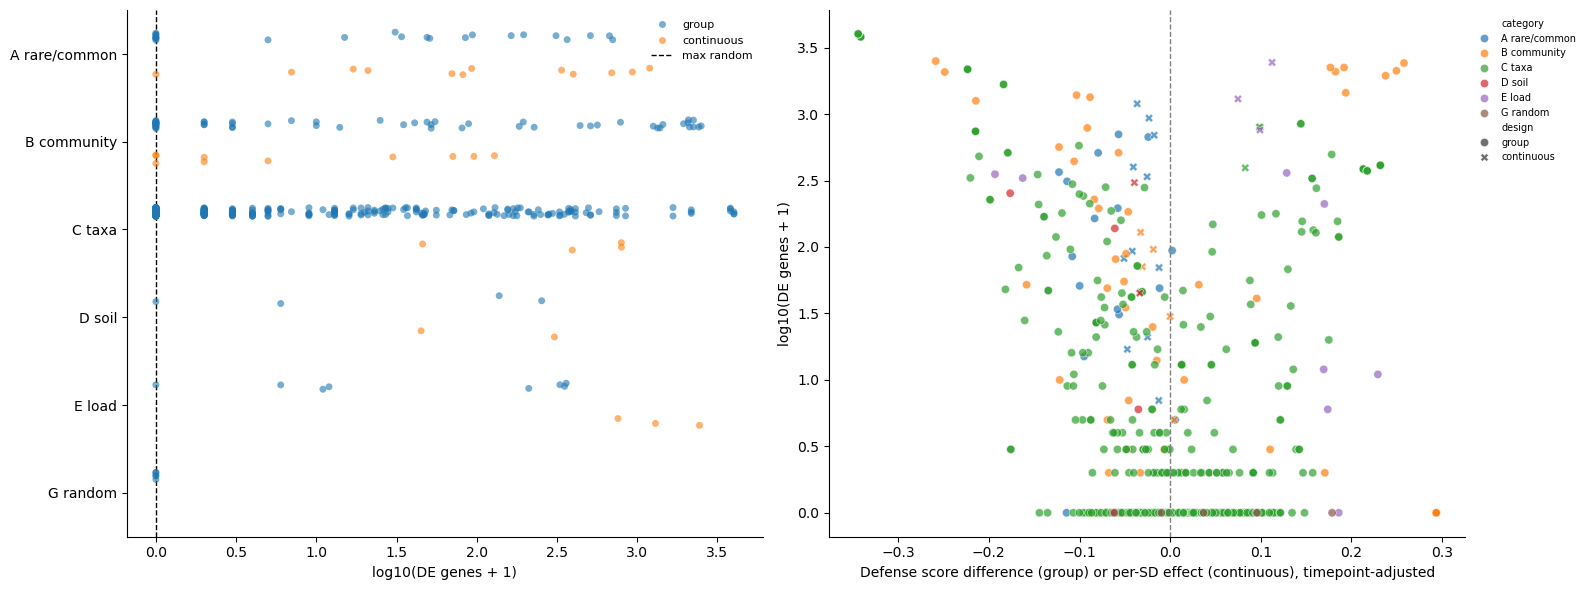

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.patch.set_facecolor("white")
plot_df = fitted.assign(log_de=np.log10(fitted["DE genes"] + 1))
sns.stripplot(data=plot_df, x="log_de", y="category", hue="design", dodge=True, alpha=0.6, ax=axes[0])
if pd.notna(random_max):
    axes[0].axvline(np.log10(random_max + 1), color="black", linestyle="dashed", linewidth=1, label="max random")
axes[0].set_xlabel("log10(DE genes + 1)")
axes[0].set_ylabel("")
axes[0].legend(frameon=False, fontsize=8)
sns.scatterplot(data=plot_df, x="defense diff", y="log_de", hue="category", style="design", alpha=0.7, ax=axes[1])
axes[1].axvline(0, color="gray", linestyle="dashed", linewidth=1)
axes[1].set_xlabel("Defense score difference (group) or per-SD effect (continuous), timepoint-adjusted")
axes[1].set_ylabel("log10(DE genes + 1)")
axes[1].legend(frameon=False, fontsize=7, bbox_to_anchor=(1, 1))
for ax in axes:
    sns.despine(ax=ax)
plt.tight_layout()

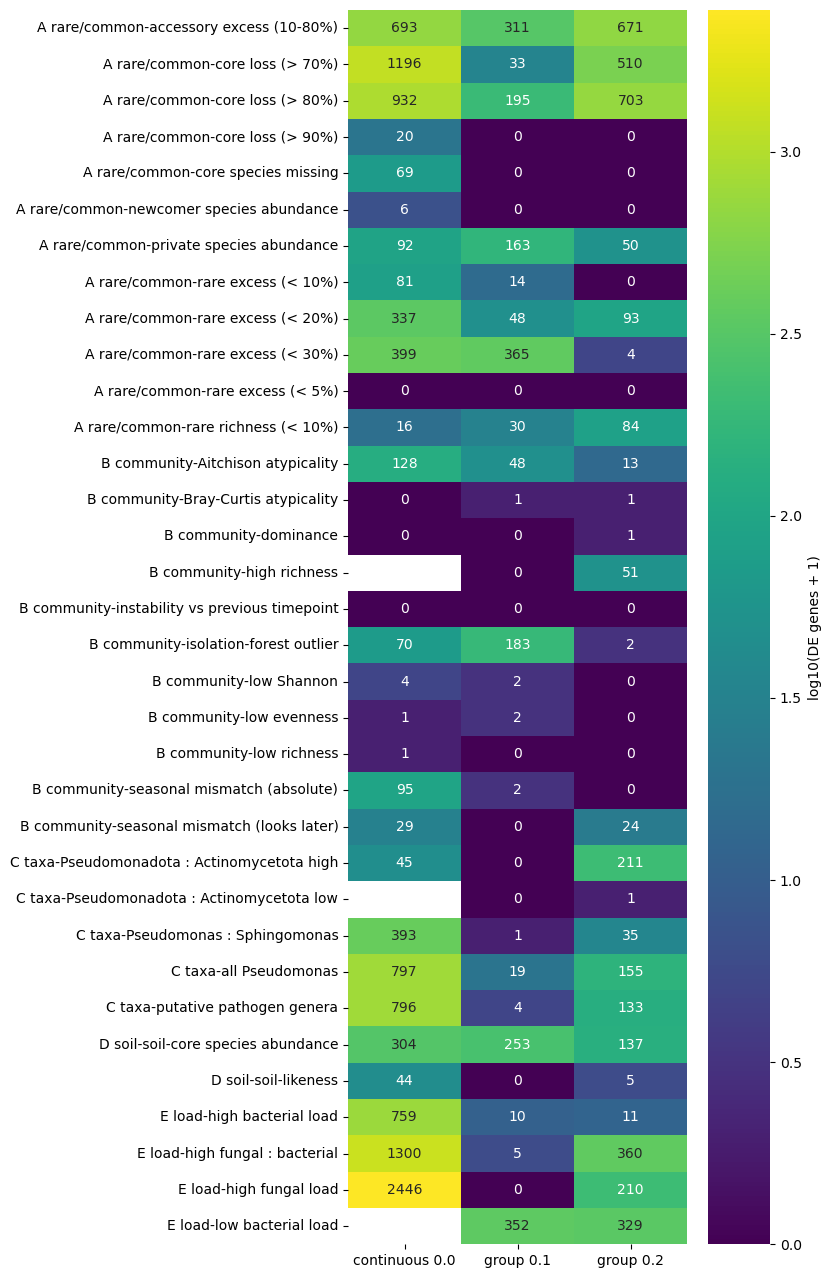

In [16]:
# Aggregate measures (A, B, D, E and the C aggregates) side by side
aggregate = fitted.loc[~fitted["name"].str.contains("bloom:|depletion:|k-means|random", regex=True)]
aggregate_table = aggregate.pivot_table(
    index=["category", "name"], columns=aggregate["design"] + " " + aggregate["fraction"].fillna(0).astype(str), values="DE genes"
)
if aggregate_table.empty:
    print("No aggregate-measure fits yet")
else:
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(aggregate_table) + 2))
    fig.patch.set_facecolor("white")
    sns.heatmap(np.log10(aggregate_table + 1), annot=aggregate_table, fmt=".0f", cmap="viridis", cbar_kws={"label": "log10(DE genes + 1)"}, ax=ax)
    ax.set_xlabel("")
    ax.set_ylabel("")
    plt.tight_layout()

## Results: non-defense transcriptome signatures

In [17]:
signature_columns = (
    ["name", "n High", "microbiome pseudo-F", "microbiome PERMANOVA p", "microbiome PERMANOVA q", "defense diff", "defense diff q"]
    + [f"{m} diff" for m in descriptor_measures.columns]
)
evaluation.loc[transcriptome_rows].sort_values("microbiome PERMANOVA p")[signature_columns].round(4)

,name,n High,microbiome pseudo-F,microbiome PERMANOVA p,microbiome PERMANOVA q,defense diff,defense diff q,bacterial load diff,fungal load diff,Shannon diff,Bray-Curtis atypicality diff,rare abundance (< 10%) diff,P. viridiflava diff
602,GO response to light stimulus low,64.0,2.2817,0.001,0.0018,-0.3595,0.0000,-0.0303,-0.1170,-0.0571,0.0055,-0.1678,-0.0980
606,GO response to UV-B low,64.0,3.4450,0.001,0.0018,-0.4872,0.0000,-0.0430,-0.1039,-0.0248,0.0086,0.2777,-0.1977
605,GO response to UV-B high,64.0,2.1665,0.001,0.0018,0.5017,0.0000,0.0041,0.0725,-0.0123,-0.0062,-0.2990,0.2998
604,GO response to high light low,64.0,2.4380,0.001,0.0018,-0.1776,0.0133,-0.0064,-0.0419,-0.0362,0.0065,-0.0006,-0.0521
610,GO response to water deprivation low,64.0,3.3496,0.001,0.0018,-0.3817,0.0000,-0.0587,-0.1780,-0.0767,0.0350,0.7130,-0.1482
...,...,...,...,...,...,...,...,...,...,...,...,...,...
651,non-immune PC2 high,64.0,1.0676,0.455,0.4740,0.0308,0.8074,-0.0292,0.0325,-0.0096,0.0025,-0.0282,0.2123
664,non-immune PC8 low,64.0,1.0674,0.456,0.4740,0.0266,0.8419,-0.0453,-0.1247,-0.0142,0.0120,0.5155,-0.0032
660,non-immune PC6 low,64.0,1.0404,0.605,0.6207,0.0923,0.3290,0.0068,-0.0020,-0.0427,0.0146,0.1352,-0.0303
659,non-immune PC6 high,64.0,1.0176,0.618,0.6259,0.1366,0.0879,-0.0100,-0.0458,-0.0485,-0.0112,-0.0891,0.1080


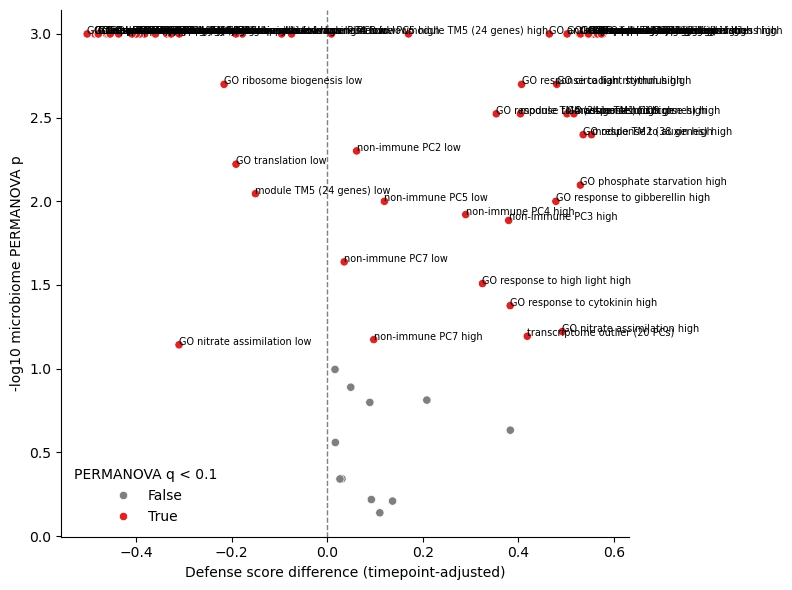

In [18]:
signature_eval = evaluation.loc[transcriptome_rows]
fig, ax = plt.subplots(figsize=(8, 6))
fig.patch.set_facecolor("white")
sns.scatterplot(
    data=signature_eval,
    x="defense diff",
    y=-np.log10(signature_eval["microbiome PERMANOVA p"]),
    hue=signature_eval["microbiome PERMANOVA q"] < 0.1,
    palette={True: "tab:red", False: "tab:gray"},
    ax=ax,
)
for _, row in signature_eval.loc[signature_eval["microbiome PERMANOVA q"] < 0.1].iterrows():
    ax.text(row["defense diff"], -np.log10(row["microbiome PERMANOVA p"]), row["name"], fontsize=7)
ax.axvline(0, color="gray", linestyle="dashed", linewidth=1)
ax.set_xlabel("Defense score difference (timepoint-adjusted)")
ax.set_ylabel("-log10 microbiome PERMANOVA p")
ax.legend(title="PERMANOVA q < 0.1", frameon=False)
sns.despine()
plt.tight_layout()

## Top microbiome definitions: genes and GO enrichment

The five non-random microbiome groupings with the most DE genes outside the defense set.

In [19]:
background_genes = de_counts.columns.tolist()
top_definitions = (
    fitted.loc[fitted["category"] != "G random"]
    .drop_duplicates("fit_id")
    .sort_values("DE genes outside defense set", ascending=False)
    .head(5)
)
for _, row in top_definitions.iterrows():
    results = pd.read_csv(results_dir / "fits" / f"{row['fit_id']}.csv", index_col=0)
    significant = results.loc[results["padj"] < 0.05].sort_values("padj")
    print(f"\n=== {row['name']} ({row['design']}, fraction {row['fraction']}): {len(significant)} DE genes ===")
    if len(significant) == 0:
        continue
    display(significant.head(15)[["baseMean", "log2FoldChange", "padj"]].assign(defense_gene=lambda df: df.index.isin(defense_genes)).round(4))
    if len(significant) >= 10:
        with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
            tables = Go_tools.generate_contigency_tables(
                go_annotations=go_term_matrix, gene_list=significant.index.tolist(),
                use_background_genes=True, background_genes=background_genes,
            )
            go_results = Go_tools.multi_hypothesis_correct_fishers_exact(
                Go_tools.fishers_exact_on_contigency_tables(all_go_contigency_tables=tables, original_GO_term_panda=go_term_matrix)
            )
        display(go_results.merge(go_term_names, left_index=True, right_index=True, how="left").sort_values("P_value").head(10))


=== Family bloom: f__Coleofasciculaceae (group, fraction 0.15): 4010 DE genes ===


,baseMean,log2FoldChange,padj,defense_gene
AT5G13510,1162.4135,0.4628,0.0,False
AT5G45380,136.9492,-1.0487,0.0,False
AT5G38410,25130.4656,0.6386,0.0,False
AT3G62030,2303.4021,0.4707,0.0,False
AT3G56910,2139.4694,0.3835,0.0,False
AT1G74970,1446.3606,0.4280,0.0,False
AT2G38140,1584.7001,0.4682,0.0,False
ArthCt089,53044.2528,0.5192,0.0,False
AT1G67090,101765.8970,0.3884,0.0,False
AT2G06520,11820.0226,0.3343,0.0,False


,P_value,x
GO:0009579,6.631612e-62,thylakoid
GO:0009535,4.604376e-57,chloroplast thylakoid membrane
GO:0009570,1.279136e-56,chloroplast stroma
GO:0009534,4.696434e-52,chloroplast thylakoid
GO:0009941,1.158215e-44,chloroplast envelope
GO:0022626,1.670016e-43,cytosolic ribosome
GO:0003729,1.280073e-40,mRNA binding
GO:0022625,3.899498e-34,cytosolic large ribosomal subunit
GO:0009507,1.201086e-31,chloroplast
GO:0006412,1.732106e-27,translation



=== Phylum bloom: p__Cyanobacteriota (group, fraction 0.15): 3810 DE genes ===


,baseMean,log2FoldChange,padj,defense_gene
AT5G38410,25130.4656,0.6383,0.0,False
AT1G17745,896.0290,-0.8700,0.0,False
AT1G74970,1446.3606,0.4431,0.0,False
AT3G62030,2303.4021,0.4638,0.0,False
AT2G38140,1584.7001,0.4773,0.0,False
AT4G21120,85.7292,-1.1443,0.0,False
AT3G05690,48.0667,-1.0518,0.0,False
AT5G35630,2069.6372,0.4024,0.0,False
AT2G43510,369.1471,-0.8408,0.0,False
AT4G16980,2109.9522,0.4994,0.0,False


,P_value,x
GO:0009535,4.128210e-69,chloroplast thylakoid membrane
GO:0009579,1.870213e-63,thylakoid
GO:0009570,2.390956e-62,chloroplast stroma
GO:0009534,2.632937e-55,chloroplast thylakoid
GO:0009941,6.662937e-52,chloroplast envelope
GO:0009507,2.102923e-34,chloroplast
GO:0022626,2.560725e-30,cytosolic ribosome
GO:0003729,1.697939e-28,mRNA binding
GO:0005829,7.819987e-26,cytosol
GO:0022625,8.097980e-25,cytosolic large ribosomal subunit


... (5 outputs left out)

,P_value,x
GO:0009535,1.133024e-93,chloroplast thylakoid membrane
GO:0009579,4.489864e-78,thylakoid
GO:0009534,6.183066e-74,chloroplast thylakoid
GO:0009941,1.271878e-57,chloroplast envelope
GO:0009570,3.359825e-57,chloroplast stroma
GO:0009507,7.041455e-41,chloroplast
GO:0048046,3.072135e-30,apoplast
GO:0042742,2.242859e-24,defense response to bacterium
GO:0009543,9.041410e-23,chloroplast thylakoid lumen
GO:0050832,6.148598e-19,defense response to fungus



=== k-means community type k=4 cluster 2 (n=194) (group, fraction 0.455): 2421 DE genes ===


,baseMean,log2FoldChange,padj,defense_gene
AT1G72610,15577.2031,-0.4009,0.0,False
AT5G45890,323.6307,5.2102,0.0,False
AT4G12730,671.2402,-0.4616,0.0,False
AT1G55670,8811.3755,-0.3726,0.0,False
AT1G52230,3263.5169,-0.3407,0.0,False
AT1G31330,33408.6617,-0.3084,0.0,False
AT4G12800,14969.7941,-0.3048,0.0,False
AT3G21055,17679.3432,-0.3859,0.0,False
AT1G22350,75.9491,0.6177,0.0,False
AT3G56940,2770.8675,-0.3584,0.0,False


,P_value,x
GO:0009535,2.810224e-49,chloroplast thylakoid membrane
GO:0009579,3.235409e-47,thylakoid
GO:0009534,2.788246e-44,chloroplast thylakoid
GO:0009941,2.032394e-36,chloroplast envelope
GO:0009570,1.130755e-31,chloroplast stroma
GO:0048046,2.487380e-23,apoplast
GO:0009507,4.233311e-20,chloroplast
GO:0009611,9.094256e-11,response to wounding
GO:0005829,1.444550e-10,cytosol
GO:0016168,2.463065e-09,chlorophyll binding
